# Text effects

A passage on a night card where five words carry their meaning: smoke curls, metal shines, wind blows,
sparks burn and snow falls. Each effect styles a range of the text, so the words stay real, selectable
text, and every effect animates with SMIL.

The project's theme applies to everything below, as it does when the project builds.

In [1]:
import svgwriter as svg

project = svg.Project.load()
theme = svg.Theme.load(project.config.theme)
theme.__enter__();

In [2]:
from animations import twinkle
from components import card

import svgwriter as svg

LINES = (
    "...into the cold night, and Smoke curled around",
    "his Metal scales. A bitter Wind carried sparks",
    "across the Snow plains, where an...",
)
EFFECT_NAMES = list(svg.text_effects.__all__)
WORDS = {"Smoke": "smoke", "Metal": "metal", "Wind": "wind", "sparks": "fire", "Snow": "snow"}
"""The starting text effect of each word, by name from ``svg.text_effects``."""
INSET = 16          # card edge to page edge
LEFT = 64           # first letter of each line
FIRST = 108         # baseline of the first line
LEADING = 54        # baseline to baseline

`line[start:end].effect(name)` moves that range of a line onto a copy just above it, so the effect's
filter reaches only those letters while the line keeps its spacing. Each word has a dropdown, so
`svgwriter preview` (or `svg.interact` in a notebook) can swap its effect.

In [3]:
def effect_choice(word: str) -> svg.widgets.Dropdown:
    """The dropdown that picks the effect of *word*."""
    return svg.widgets.Dropdown(EFFECT_NAMES, value=WORDS[word], label=word)


@svg.widgets.controls(smoke=effect_choice("Smoke"), metal=effect_choice("Metal"), wind=effect_choice("Wind"),
                      sparks=effect_choice("sparks"), snow=effect_choice("Snow"))
def passage(doc: svg.Document, *, smoke: str = "smoke", metal: str = "metal", wind: str = "wind",
            sparks: str = "fire", snow: str = "snow") -> svg.Document:
    """Draw the card and the passage, with the chosen effect on each of the five words."""
    box = doc.root.get("viewBox")
    sky = card(box.width, box.height, inset=INSET, caption="svg.text_effects")
    doc += sky
    sky.children[2].animate.apply(twinkle)
    effects = {"Smoke": smoke, "Metal": metal, "Wind": wind, "sparks": sparks, "Snow": snow}
    for row, words in enumerate(LINES):
        line = doc.text(words, x=LEFT, y=FIRST + row * LEADING).as_role("text")
        for word, effect in effects.items():
            if word in words:
                start = words.index(word)
                line[start:start + len(word)].effect(effect)
    return doc

Every control of `passage` becomes an input: in a running notebook (with the `widget` extra) this panel redraws the drawing as you change them. A saved notebook cannot keep live widgets, so the stills below show other values.

In [4]:
import functools

from IPython import display as ipy


def in_project(function):
    @functools.wraps(function)
    def draw(doc, **values):
        size = project.config.size
        sheet = svg.Document(*size, theme=theme) if isinstance(size, tuple) else svg.Document(size=size, theme=theme)
        with theme:
            result = function(sheet, **values)
        return sheet if result is None else result

    return draw


def show(function, **values):
    ipy.display(ipy.SVG(data=in_project(function)(None, **values).to_string()))


svg.interact(in_project(passage))

The same function for other control values.

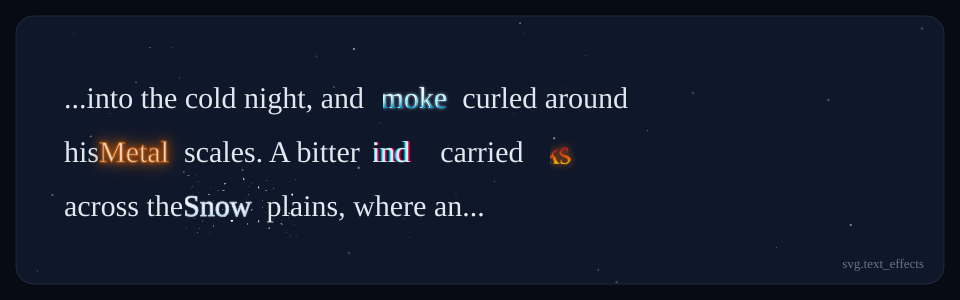

In [5]:
show(passage, **{'smoke': 'ice', 'metal': 'neon', 'wind': 'glitch'})

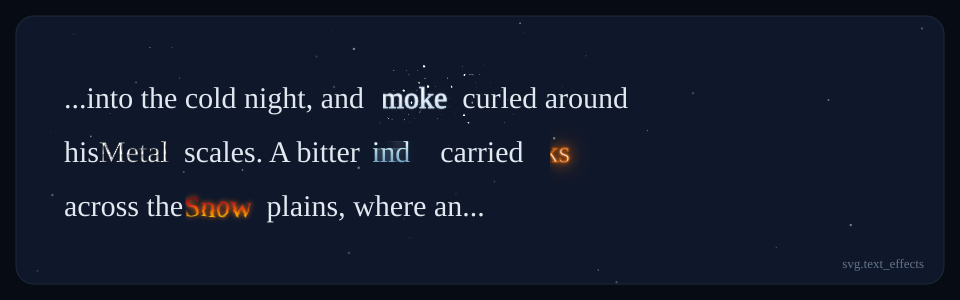

In [6]:
show(passage, **{'sparks': 'neon', 'snow': 'fire', 'smoke': 'snow'})

`project.build` writes the outputs listed in `svgwriter.toml` (here only the SVG, which keeps animations as SMIL) and the notebook shows each one.

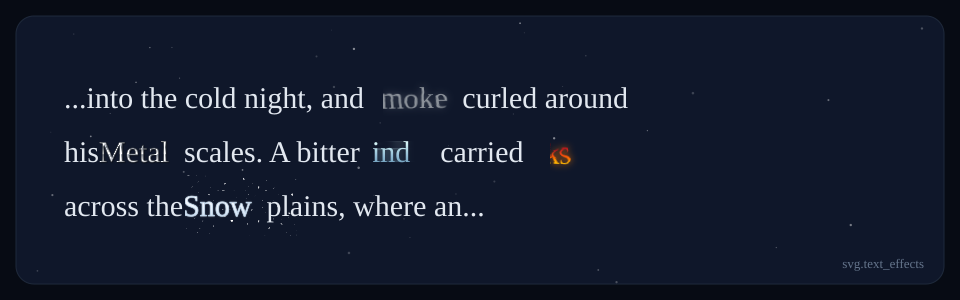

In [7]:
for path in project.build(["svg"]):
    ipy.display(ipy.SVG(filename=str(path)))